In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import librosa                      
import librosa.display            
from IPython.display import Audio
DATA_DIR = Path.home() / "Datasets" / "IRMAS" / "IRMAS-TrainingData"    
instruments = sorted([p.name for p in DATA_DIR.iterdir() if p.is_dir()])  
print(instruments)                 

['cel', 'cla', 'flu', 'gac', 'gel', 'org', 'pia', 'sax', 'tru', 'vio', 'voi']


In [10]:
total = 0
for inst in instruments:
    files = [f for f in(DATA_DIR / inst).iterdir() if f.suffix == ".wav"]
    print(inst, len(files))
    total += len(files)
print("总共", total)


cel 388
cla 505
flu 451
gac 637
gel 760
org 682
pia 721
sax 626
tru 577
vio 580
voi 778
总共 6705


004__[cla][nod][cla]0242__1.wav 22050 3.0 秒


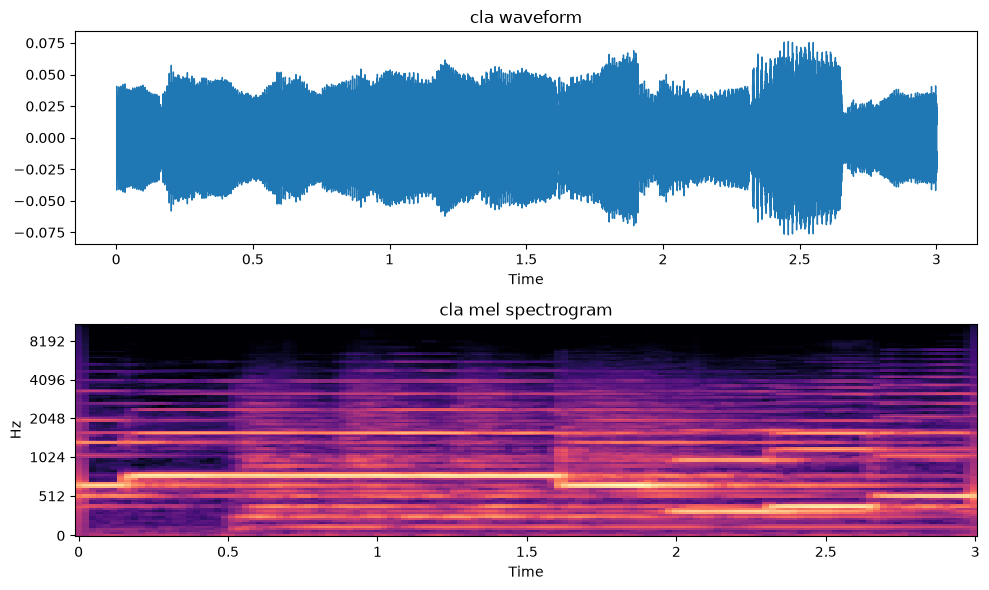

In [11]:
inst = "cla"                                   # 选一种乐器，pia 是钢琴
file = sorted((DATA_DIR / inst).iterdir())[0]  # 列出钢琴文件夹里所有文件，排序，取第一个
y, sr = librosa.load(file)                     # 读取音频：y 是声音数据（一串数字），sr 是采样率
print(file.name, sr, len(y) / sr, "秒")        # 打印文件名、采样率、时长（数据点个数 ÷ 采样率 = 秒数）

display(Audio(y, rate=sr))                     # 在 notebook 里显示一个播放器，可以点开听

fig, ax = plt.subplots(2, 1, figsize=(10, 6))  # 建一张画布，上下两个子图，宽 10 高 6
librosa.display.waveshow(y, sr=sr, ax=ax[0])   # 在上面的子图画波形
ax[0].set_title(f"{inst} waveform")            # 上图标题

S = librosa.feature.melspectrogram(y=y, sr=sr) # 计算 mel 频谱（每个时刻各个频率的能量）
S_db = librosa.power_to_db(S, ref=np.max)      # 把能量换算成分贝（dB），更接近人耳感受，图也更清楚
librosa.display.specshow(S_db, sr=sr, x_axis="time", y_axis="mel", ax=ax[1])  # 在下面的子图画 mel 频谱，横轴时间，纵轴 mel 频率
ax[1].set_title(f"{inst} mel spectrogram")     # 下图标题
plt.tight_layout()                             # 自动调整间距，防止标题和图重叠

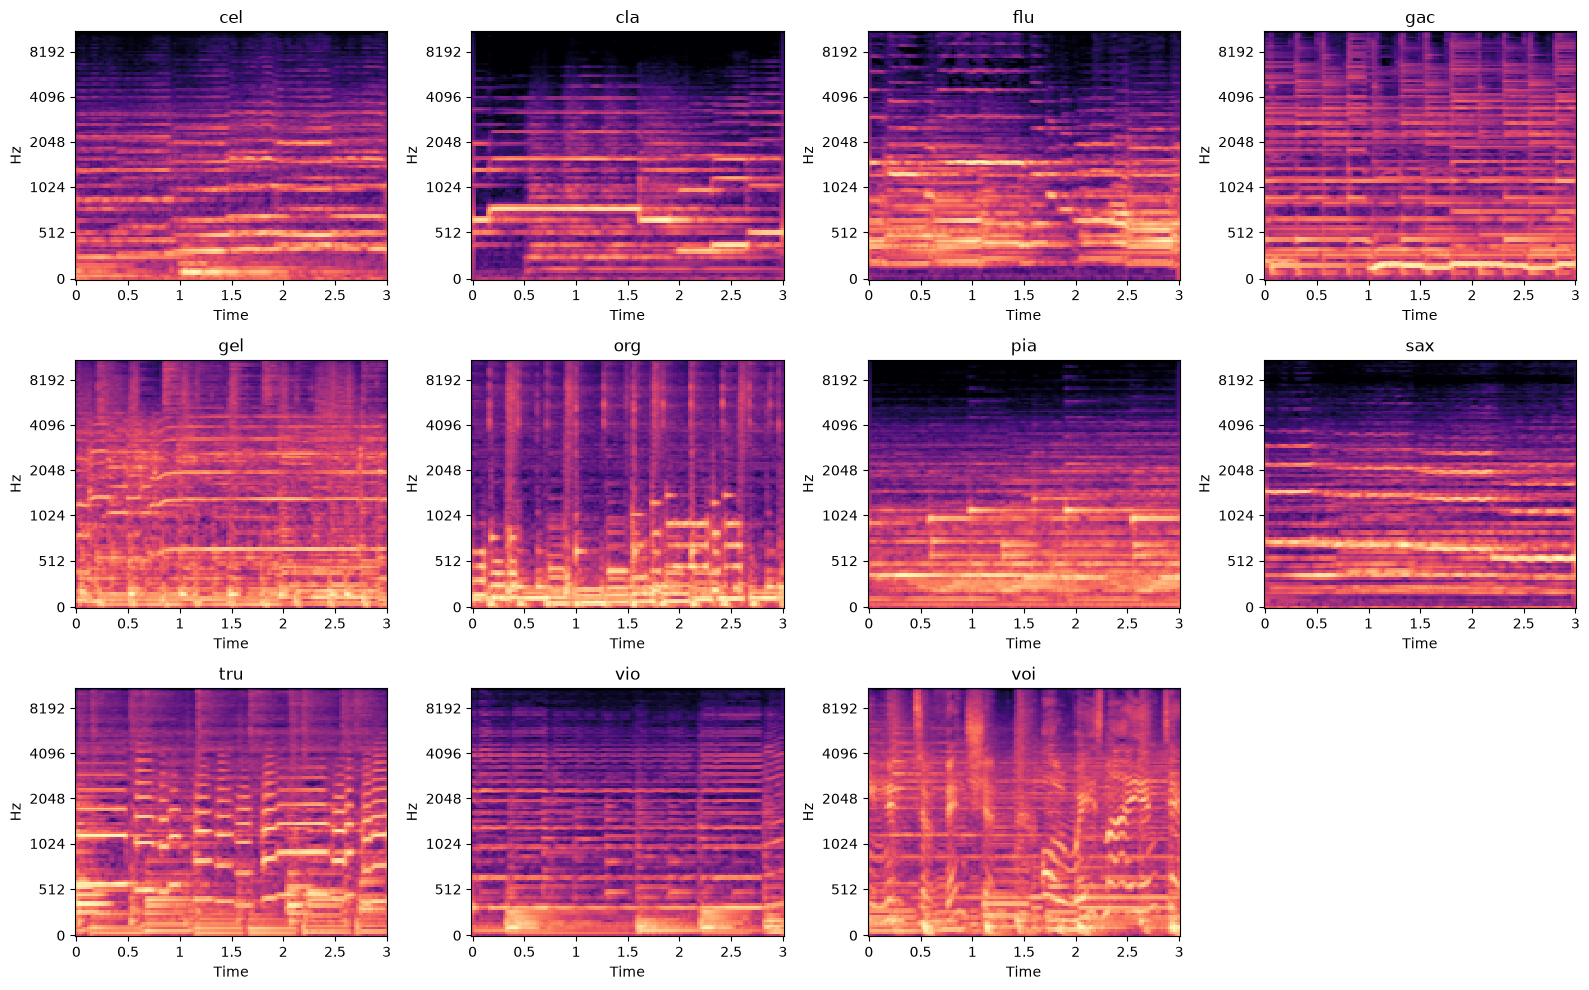

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))          # 建一张画布，3 行 4 列共 12 个子图，宽 16 高 10
axes = axes.flatten()                                      # 把 3×4 的子图排成一列，方便用 0 到 11 的编号取
for i, inst in enumerate(instruments):                     # 遍历每种乐器，i 是编号（0、1、2……），inst 是乐器名
    file = sorted((DATA_DIR / inst).iterdir())[0]          # 取这个乐器文件夹里的第一个文件
    y, sr = librosa.load(file)                             # 读取音频
    S = librosa.feature.melspectrogram(y=y, sr=sr)         # 计算 mel 频谱
    S_db = librosa.power_to_db(S, ref=np.max)              # 换算成分贝
    librosa.display.specshow(S_db, sr=sr, x_axis="time", y_axis="mel", ax=axes[i])  # 画到第 i 个子图上
    axes[i].set_title(inst)                                # 子图标题写乐器名
axes[-1].axis("off")                                       # 一共 12 个格子只用了 11 个，把最后一个空格子隐藏
plt.tight_layout()                                         # 自动调整间距

(13, 130)
(26,)
[-368.92  208.58  -22.5    19.39   -4.76   -5.97    2.21   -0.77   -4.95
  -16.08  -18.84   -3.44    4.81   24.87   13.41    9.88    7.29    6.06
    8.27    4.69    6.59    8.76    6.11    6.27    7.42    4.87]


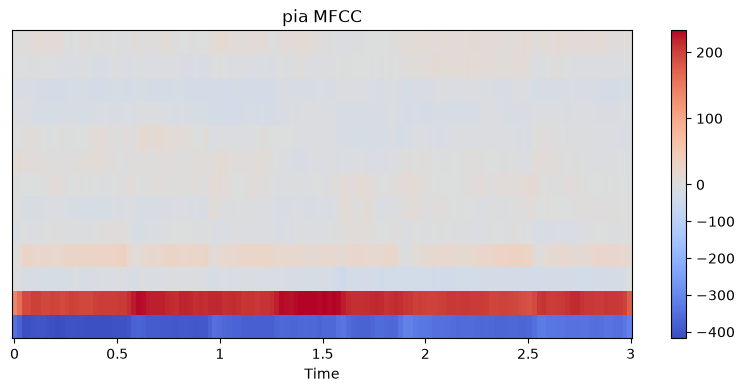

In [13]:
inst = "pia"                                           # 选钢琴
file = sorted((DATA_DIR / inst).iterdir())[0]          # 取第一个文件
y, sr = librosa.load(file)                             # 读取音频

mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)     # 提取 13 个 MFCC 系数
print(mfcc.shape)                                      # 打印形状：(13, 时间帧数)

feat = np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)])  # 每个系数沿时间求平均值和标准差，拼在一起
print(feat.shape)                                      # 打印形状：(26,)，一段音频变成 26 个数字
print(feat.round(2))                                   # 打印这 26 个数字，保留两位小数

fig, ax = plt.subplots(figsize=(10, 4))                # 建画布
librosa.display.specshow(mfcc, sr=sr, x_axis="time", ax=ax)  # 画 MFCC，横轴时间，纵轴 13 个系数
ax.set_title(f"{inst} MFCC")                           # 标题
plt.colorbar(ax.collections[0], ax=ax)                 # 加颜色条，看数值大小

In [14]:
def extract_features(file):                                         # 定义函数：输入一个音频文件，输出一组特征
    y, sr = librosa.load(file)                                       # 读取音频
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)               # 13 个 MFCC，描述音色
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)         # 频谱质心：声音有多“亮”
    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)       # 频谱带宽：频率分布得宽还是窄
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)           # 频谱滚降点：85% 能量在多少 Hz 以下
    zcr = librosa.feature.zero_crossing_rate(y)                      # 过零率：噪声、辅音多时高
    rms = librosa.feature.rms(y=y)                                   # 响度
    frames = np.vstack([mfcc, centroid, bandwidth, rolloff, zcr, rms])  # 上下拼成一张表：13 + 5 = 18 行
    return np.concatenate([frames.mean(axis=1), frames.std(axis=1)])    # 每行求平均值和标准差，得到 36 个数字

feat = extract_features(file)    # 用第五格那段钢琴测试
print(feat.shape)                # 应该打印 (36,)

(36,)


In [ ]:
X = []                                                    # 存所有特征，每段音频一行
labels = []                                               # 存每段音频对应的乐器名
for inst in instruments:                                  # 遍历每种乐器
    files = [f for f in (DATA_DIR / inst).iterdir() if f.suffix == ".wav"]  # 拿到这个乐器的所有 wav
    for f in files:                                       # 遍历每个文件
        X.append(extract_features(f))                     # 提特征，加进 X
        labels.append(inst)                               # 记下乐器名
    print(inst, "完成")                                   # 每做完一种乐器打印一下，看进度

X = np.array(X)                                           # 列表转成矩阵：6705 行 × 36 列
labels = np.array(labels)                                 # 乐器名也转成数组
print(X.shape, labels.shape)                              # 应该打印 (6705, 36) (6705,)

np.savez(DATA_DIR.parent / "features.npz", X=X, labels=labels)  # 存到 ~/Datasets/IRMAS/features.npz，下次直接读

cel 完成
cla 完成
flu 完成
